# 02. Recreación del análisis del artículo y comparación de resultados

Recreación con datos simulados de Imtiaz et al. (2025), *Computers and Electronics in Agriculture*, 237, 110636.

Este notebook aplica el procedimiento del artículo a la base simulada: partición aleatoria 70/30 dentro de cada parcela, modelos CART, RF y GTB con los hiperparámetros de la Tabla 3, y métricas R², RMSE y MAE. A diferencia del artículo, que usó una sola partición, el procedimiento se repite en **30 réplicas** (30 bases simuladas con semillas distintas), para estimar la variabilidad de los resultados y obtener intervalos de confianza.

## 1. Configuración

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

from src import config
from src.evaluacion import ejecutar_recreacion

sns.set_theme(style="whitegrid", context="notebook")
print("Réplicas:", config.N_REPLICAS)
print("Modelos:", config.MODELOS)

Réplicas: 30
Modelos: ['CART', 'RF', 'GTB']


## 2. Recreación con 30 réplicas

En cada réplica se genera una base con la semilla `42 + número de réplica` (la réplica 0 es la base publicada en `data/`) y se aplica el procedimiento del artículo a cada combinación de:

- 4 parcelas × 2 sensores × 2 estrategias × 3 modelos.
- En B y D, dos respuestas: el **rendimiento interpolado** (recreación fiel del artículo) y el **rendimiento real** (contraste).

En total, 72 evaluaciones por réplica y 2.160 en las 30 réplicas. Los resultados se guardan en `results/02_replicas.csv`; si el archivo ya existe, se leen sin volver a entrenar.

In [2]:
replicas = ejecutar_recreacion()
print(replicas.shape)
replicas.head()

Réplica 1/30 terminada (0.4 min)
Réplica 2/30 terminada (0.8 min)
Réplica 3/30 terminada (1.2 min)
Réplica 4/30 terminada (1.6 min)
Réplica 5/30 terminada (2.0 min)
Réplica 6/30 terminada (2.4 min)
Réplica 7/30 terminada (2.8 min)
Réplica 8/30 terminada (3.2 min)
Réplica 9/30 terminada (3.6 min)
Réplica 10/30 terminada (4.0 min)
Réplica 11/30 terminada (4.4 min)
Réplica 12/30 terminada (4.8 min)
Réplica 13/30 terminada (5.3 min)
Réplica 14/30 terminada (5.7 min)
Réplica 15/30 terminada (6.1 min)
Réplica 16/30 terminada (6.5 min)
Réplica 17/30 terminada (6.9 min)
Réplica 18/30 terminada (7.3 min)
Réplica 19/30 terminada (7.7 min)
Réplica 20/30 terminada (8.2 min)
Réplica 21/30 terminada (8.7 min)
Réplica 22/30 terminada (9.2 min)
Réplica 23/30 terminada (9.7 min)
Réplica 24/30 terminada (10.1 min)
Réplica 25/30 terminada (10.5 min)
Réplica 26/30 terminada (10.9 min)
Réplica 27/30 terminada (11.3 min)
Réplica 28/30 terminada (11.8 min)
Réplica 29/30 terminada (12.2 min)
Réplica 30/30 ter

,parcela,sensor,estrategia,modelo,respuesta,semilla,ent_r2,ent_r2_corr,ent_rmse,ent_mae,pru_r2,pru_r2_corr,pru_rmse,pru_mae,replica
0,A,PlanetScope,multivariada,CART,rendimiento,42,0.997232,0.997232,0.559409,0.420710,0.654571,0.678545,5.421135,4.411153,0
1,A,PlanetScope,multivariada,RF,rendimiento,42,0.915798,0.917620,3.085649,2.443936,0.801147,0.810827,4.113177,3.365532,0
2,A,PlanetScope,multivariada,GTB,rendimiento,42,0.991384,0.992674,0.987020,0.493458,0.777662,0.792598,4.349281,3.644079,0
3,A,PlanetScope,univariada,CART,rendimiento,42,0.997043,0.997043,0.578292,0.432454,0.685602,0.708201,5.171904,4.034684,0
4,A,PlanetScope,univariada,RF,rendimiento,42,0.937040,0.938466,2.668203,2.111524,0.845215,0.850978,3.628906,2.880079,0


**Resultado.** Las 30 réplicas produjeron 2.160 evaluaciones (30 réplicas × 72 combinaciones), con 15 columnas: identificación del experimento (parcela, sensor, estrategia, modelo, respuesta, semilla y réplica) y las cuatro métricas (R², r², RMSE y MAE) en entrenamiento (`ent_`) y en prueba (`pru_`). La ejecución completa tomó unos 13 minutos; los resultados quedan guardados en `results/02_replicas.csv` para que puedan revisarse sin volver a entrenar los modelos.

## 3. Comparación con las Tablas 4 y 5

Se compara el **escenario fiel al artículo**: estrategia multivariada; en A y C, el rendimiento real (datos de cosechadora); en B y D, el rendimiento interpolado desde 30 mediciones, como hicieron los autores.

Para cada parcela, sensor y modelo se calcula la media de las 30 réplicas y el intervalo que contiene el 95 % central de los resultados (percentiles 2,5 y 97,5). Si el valor del artículo cae dentro del intervalo, es compatible con la simulación; si cae fuera, la diferencia requiere explicación.

,parcela,sensor,modelo,media,ic_inf,ic_sup,articulo,dentro_ic
48,A,PlanetScope,CART,0.69,0.54,0.77,0.77,True
49,A,PlanetScope,GTB,0.80,0.71,0.85,0.72,True
50,A,PlanetScope,RF,0.82,0.75,0.87,0.68,False
51,A,Sentinel-2,CART,0.70,0.57,0.82,0.76,True
52,A,Sentinel-2,GTB,0.80,0.72,0.87,0.78,True
53,A,Sentinel-2,RF,0.83,0.78,0.87,0.72,False
54,B,PlanetScope,CART,-1.09,-1.67,-0.48,0.60,False
55,B,PlanetScope,GTB,-0.24,-0.50,-0.01,0.68,False
56,B,PlanetScope,RF,-0.05,-0.16,0.04,0.61,False
57,B,Sentinel-2,CART,-1.03,-1.86,-0.50,0.60,False


Proporción de valores del artículo dentro del intervalo del 95 %:
metrica
mae     0.58
r2      0.33
rmse    0.58
Name: dentro_ic, dtype: float64


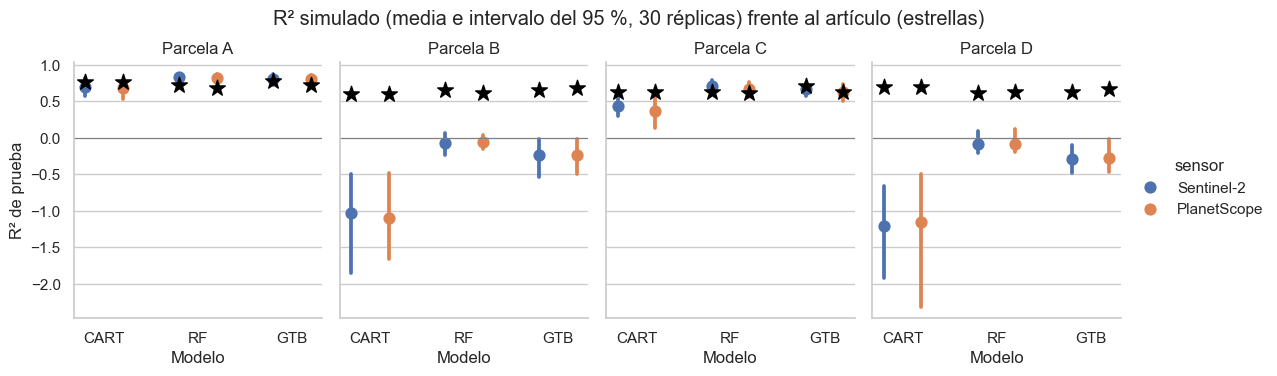

In [3]:
# Escenario fiel al artículo
es_fiel = (replicas["estrategia"] == "multivariada") & (
    (replicas["parcela"].isin(["A", "C"]) & (replicas["respuesta"] == "rendimiento"))
    | (replicas["parcela"].isin(["B", "D"]) & (replicas["respuesta"] == "rendimiento_interpolado"))
)
fiel = replicas[es_fiel]

def intervalo(serie):
    """Media e intervalo del 95 % (percentiles 2,5 y 97,5) entre réplicas."""
    return pd.Series({"media": serie.mean(),
                      "ic_inf": serie.quantile(0.025),
                      "ic_sup": serie.quantile(0.975)})

# Posición de cada métrica en config.METRICAS_ARTICULO: (RMSE, MAE, R²)
posicion = {"pru_rmse": 0, "pru_mae": 1, "pru_r2": 2}
tablas = []
for metrica, i in posicion.items():
    t = (fiel.groupby(["parcela", "sensor", "modelo"])[metrica]
         .apply(intervalo).unstack().reset_index())
    t["metrica"] = metrica.replace("pru_", "")
    t["articulo"] = [config.METRICAS_ARTICULO[s][p][m][i]
                     for p, s, m in zip(t["parcela"], t["sensor"], t["modelo"])]
    t["dentro_ic"] = (t["articulo"] >= t["ic_inf"]) & (t["articulo"] <= t["ic_sup"])
    tablas.append(t)
comparacion = pd.concat(tablas, ignore_index=True)
comparacion.to_csv(config.DIR_RESULTADOS / "02_comparacion_tablas_4_5.csv", index=False)

# R²: tabla y proporción de valores del artículo dentro del intervalo
display(comparacion[comparacion["metrica"] == "r2"].drop(columns="metrica").round(2))
print("Proporción de valores del artículo dentro del intervalo del 95 %:")
print(comparacion.groupby("metrica")["dentro_ic"].mean().round(2))

# Gráfica: R² simulado frente al artículo
g = sns.catplot(data=fiel, x="modelo", y="pru_r2", hue="sensor", col="parcela", kind="point",
                errorbar=("pi", 95), dodge=0.4, linestyle="none", order=config.MODELOS,
                hue_order=config.SENSORES, height=3.6, aspect=0.8)
desplazamiento = {"Sentinel-2": -0.2, "PlanetScope": 0.2}
for parcela, ax in g.axes_dict.items():
    for sensor in config.SENSORES:
        for k, modelo in enumerate(config.MODELOS):
            ax.scatter(k + desplazamiento[sensor], config.METRICAS_ARTICULO[sensor][parcela][modelo][2],
                       marker="*", s=140, color="black", zorder=5)
    ax.axhline(0, color="gray", lw=0.8)
g.set_axis_labels("Modelo", "R² de prueba")
g.set_titles("Parcela {col_name}")
g.figure.suptitle("R² simulado (media e intervalo del 95 %, 30 réplicas) frente al artículo (estrellas)", y=1.04)
g.savefig(config.DIR_FIGURAS / "02_r2_vs_articulo.png", dpi=150)
plt.show()

**Resultado.**

*Parcelas A y C (cosechadora): la recreación es compatible con el artículo.* En 8 de los 12 casos, el R² del artículo cae dentro del intervalo del 95 % de la simulación. Las cuatro diferencias corresponden al orden de los modelos: RF supera al artículo en A (0,82–0,83 frente a 0,68–0,72) y CART queda por debajo en C (0,36–0,44 frente a 0,62–0,63). En la simulación, RF y GTB superan sistemáticamente a CART, como predice la teoría para un árbol único con muy pocas observaciones por hoja; en el artículo, los tres modelos rinden parecido.

*Parcelas B y D (excavación): la recreación fiel no reproduce el artículo.* Ninguno de los 12 valores cae dentro del intervalo. El artículo reporta R² de 0,60–0,69; la simulación, con la superficie interpolada como respuesta, obtiene entre −1,21 y −0,05: ningún modelo supera al promedio de la parcela.

*RMSE y MAE frente a R².* El RMSE y el MAE coinciden con el artículo con más frecuencia que el R² (58 % frente a 33 % de los casos). La superficie interpolada varía mucho menos que el lote real (desviación de ~3,7 frente a ~6,2 t/ha en B), por lo que errores parecidos en t/ha equivalen a R² muy distintos. El RMSE por sí solo no basta para comparar desempeños entre escenarios con distinta variabilidad de la respuesta.

*Lectura.* Los R² del artículo en B y D son compatibles con modelos evaluados frente a una respuesta con la variabilidad de un lote real, no frente a una superficie interpolada desde 30 mediciones con manchas de 30 a 50 m. La sección 7 compara ambas respuestas, y la extensión pondrá a prueba si con manchas de mayor tamaño la interpolación conserva suficiente variabilidad para explicar los resultados del artículo.

## 4. Las dos versiones del R² (hallazgo 1)

En la parcela A con Sentinel-2, el artículo reporta para CART un RMSE menor y un R² menor que para GTB, algo imposible si ambos se calcularon con la ecuación 5 sobre el mismo conjunto de prueba. Se ponen a prueba dos explicaciones: (A) cada modelo se evaluó con una partición distinta, o (B) el R² reportado es el r² (cuadrado de la correlación entre observado y predicho).

**Análisis 1.** Diferencia entre r² y R² en la simulación (escenario fiel).

**Análisis 2.** Varianza implícita del conjunto de prueba, Var = RMSE² / (1 − R²). Si los tres modelos se evaluaron sobre el mismo conjunto con la ecuación 5, la varianza implícita es idéntica para los tres y la razón entre la mayor y la menor es 1. Se calcula esa razón en la simulación (con R² y con r²) y en el artículo.

In [4]:
# Análisis 1: R² (ecuación 5) frente a r² (correlación al cuadrado)
dos_r2 = fiel.groupby(["parcela", "sensor", "modelo"])[["pru_r2", "pru_r2_corr"]].mean()
dos_r2["articulo"] = [config.METRICAS_ARTICULO[s][p][m][2] for p, s, m in dos_r2.index]
dos_r2["diferencia_r2corr_r2"] = dos_r2["pru_r2_corr"] - dos_r2["pru_r2"]
display(dos_r2.round(2))

# Análisis 2: razón entre la mayor y la menor varianza implícita de los tres modelos
fiel_var = fiel.assign(
    var_con_r2=fiel["pru_rmse"] ** 2 / (1 - fiel["pru_r2"]),
    var_con_r2corr=fiel["pru_rmse"] ** 2 / (1 - fiel["pru_r2_corr"]),
)
razon = lambda s: s.max() / s.min()
simulada = (fiel_var.groupby(["replica", "parcela", "sensor"])[["var_con_r2", "var_con_r2corr"]]
            .agg(razon).groupby(["parcela", "sensor"]).mean())

razon_articulo = {}
for sensor in config.SENSORES:
    for parcela in config.PARCELAS:
        v = [config.METRICAS_ARTICULO[sensor][parcela][m][0] ** 2
             / (1 - config.METRICAS_ARTICULO[sensor][parcela][m][2]) for m in config.MODELOS]
        razon_articulo[(parcela, sensor)] = max(v) / min(v)
simulada["articulo"] = pd.Series(razon_articulo)
display(simulada.round(2))

pd.concat({"dos_r2": dos_r2.reset_index(), "varianza": simulada.reset_index()}) \
  .to_csv(config.DIR_RESULTADOS / "02_hallazgo1_dos_r2.csv")

pru_r2  pru_r2_corr  articulo  \
parcela sensor      modelo                                  
A       PlanetScope CART      0.69         0.71      0.77   
                    GTB       0.80         0.81      0.72   
                    RF        0.82         0.83      0.68   
        Sentinel-2  CART      0.70         0.73      0.76   
                    GTB       0.80         0.81      0.78   
                    RF        0.83         0.84      0.72   
B       PlanetScope CART     -1.09         0.01      0.60   
                    GTB      -0.24         0.01      0.68   
                    RF       -0.05         0.02      0.61   
        Sentinel-2  CART     -1.03         0.01      0.60   
                    GTB      -0.24         0.01      0.65   
                    RF       -0.07         0.02      0.65   
C       PlanetScope CART      0.36         0.48      0.63   
                    GTB       0.62         0.64      0.62   
                    RF        0.67         0.68      0.61   
        Sentinel-2  CART      0.44         0.54      0.62   
                    GTB       0.67         0.69      0.71   
                    RF        0.71         0.72      0.63   
D       PlanetScope CART     -1.15         0.01      0.69   
                    GTB      -0.28         0.02      0.67   
                    RF       -0.09         0.02      0.62   
        Sentinel-2  CART     -1.21         0.01      0.69   
                    GTB      -0.28         0.01      0.62   
                    RF       -0.09         0.02      0.61   

                            diferencia_r2corr_r2  
parcela sensor      modelo                        
A       PlanetScope CART                    0.03  
                    GTB                     0.01  
                    RF                      0.01  
        Sentinel-2  CART                    0.03  
                    GTB                     0.01  
                    RF                      0.01  
B       PlanetScope CART                    1.10  
                    GTB                     0.25  
                    RF                      0.07  
        Sentinel-2  CART                    1.05  
                    GTB                     0.26  
                    RF                      0.09  
C       PlanetScope CART                    0.12  
                    GTB                     0.02  
                    RF                      0.01  
        Sentinel-2  CART                    0.10  
                    GTB                     0.01  
                    RF                      0.01  
D       PlanetScope CART                    1.16  
                    GTB                     0.29  
                    RF                      0.11  
        Sentinel-2  CART                    1.22  
                    GTB                     0.30  
                    RF                      0.10

var_con_r2  var_con_r2corr  articulo
parcela sensor                                           
A       PlanetScope         1.0            1.08      1.44
        Sentinel-2          1.0            1.10      1.86
B       PlanetScope         1.0            1.97      1.12
        Sentinel-2          1.0            1.88      1.11
C       PlanetScope         1.0            1.20      1.18
        Sentinel-2          1.0            1.19      1.22
D       PlanetScope         1.0            1.96      1.47
        Sentinel-2          1.0            2.02      1.76

**Resultado.**

*Análisis 1: el r² no explica las diferencias con el artículo.* En A y C, con RF y GTB, el r² supera al R² en apenas 0,01–0,02; con CART, en 0,03–0,12. En B y D el r² es de 0,01–0,02, tan lejos del artículo (0,60–0,69) como el R². Aunque los autores hubieran reportado el r², eso no explicaría las diferencias principales.

*Análisis 2: varianza implícita.* En la simulación, con el R² de la ecuación 5, la razón entre la mayor y la menor varianza implícita es exactamente 1,0 en todas las combinaciones, como corresponde a tres modelos evaluados sobre el mismo conjunto de prueba (control). En el artículo, la razón va de 1,11 a 1,86 en las ocho combinaciones de parcela y sensor; el redondeo a dos decimales solo explicaría razones de hasta ~1,03. Por lo tanto, en ninguna combinación los tres modelos del artículo se evaluaron con la ecuación 5 sobre un mismo conjunto de prueba.

| Parcela | Razón con r² (simulación) | Razón en el artículo | Lectura |
|---|---|---|---|
| A | 1,08–1,10 | 1,44–1,86 | El r² no alcanza a explicarla: apunta a particiones distintas por modelo |
| C | 1,19–1,20 | 1,18–1,22 | Compatible con que se haya reportado el r² |

*Actualización del hallazgo 1.* La inconsistencia entre R² y RMSE no se limita a la parcela A, como se supuso en la caracterización inicial: afecta a las ocho combinaciones de parcela y sensor. En C es compatible con el uso del r²; en A sugiere particiones distintas para cada modelo. En ambos casos, los R² del artículo no deberían compararse directamente entre modelos, porque no provienen de un mismo conjunto de prueba con una misma métrica.

## 5. R² de entrenamiento (hallazgo 13)

Con la configuración del artículo (CART con 100–150 hojas para ~210 puntos de entrenamiento y GTB con nodos ilimitados), los modelos deberían ajustarse casi perfectamente a los datos de entrenamiento. Se compara el R² de entrenamiento simulado con el reportado en las Tablas 4 y 5, junto con la brecha entre entrenamiento y prueba, que mide el sobreajuste.

In [5]:
# R² de entrenamiento reportado en el artículo (Tablas 4 y 5) [R]
r2_entrenamiento_articulo = {
    "Sentinel-2": {"A": {"CART": 0.82, "RF": 0.78, "GTB": 0.84},
                   "B": {"CART": 0.67, "RF": 0.72, "GTB": 0.72},
                   "C": {"CART": 0.70, "RF": 0.70, "GTB": 0.78},
                   "D": {"CART": 0.75, "RF": 0.68, "GTB": 0.70}},
    "PlanetScope": {"A": {"CART": 0.82, "RF": 0.75, "GTB": 0.78},
                    "B": {"CART": 0.66, "RF": 0.68, "GTB": 0.74},
                    "C": {"CART": 0.69, "RF": 0.67, "GTB": 0.70},
                    "D": {"CART": 0.74, "RF": 0.70, "GTB": 0.72}},
}

entrenamiento = fiel.groupby(["parcela", "sensor", "modelo"])[["ent_r2", "pru_r2"]].mean()
entrenamiento["brecha_sim"] = entrenamiento["ent_r2"] - entrenamiento["pru_r2"]
entrenamiento["ent_r2_art"] = [r2_entrenamiento_articulo[s][p][m] for p, s, m in entrenamiento.index]
entrenamiento["pru_r2_art"] = [config.METRICAS_ARTICULO[s][p][m][2] for p, s, m in entrenamiento.index]
entrenamiento["brecha_art"] = entrenamiento["ent_r2_art"] - entrenamiento["pru_r2_art"]
display(entrenamiento.round(2))
entrenamiento.to_csv(config.DIR_RESULTADOS / "02_hallazgo13_entrenamiento.csv")

# Resumen por modelo
resumen_modelo = entrenamiento.groupby("modelo")[["ent_r2", "ent_r2_art", "brecha_sim", "brecha_art"]].mean()
display(resumen_modelo.round(2))

ent_r2  pru_r2  brecha_sim  ent_r2_art  \
parcela sensor      modelo                                           
A       PlanetScope CART      1.00    0.69        0.31        0.82   
                    GTB       0.99    0.80        0.19        0.78   
                    RF        0.89    0.82        0.07        0.75   
        Sentinel-2  CART      1.00    0.70        0.30        0.82   
                    GTB       1.00    0.80        0.20        0.84   
                    RF        0.90    0.83        0.07        0.78   
B       PlanetScope CART      0.98   -1.09        2.07        0.66   
                    GTB       0.97   -0.24        1.21        0.74   
                    RF        0.38   -0.05        0.43        0.68   
        Sentinel-2  CART      0.98   -1.03        2.01        0.67   
                    GTB       0.98   -0.24        1.22        0.72   
                    RF        0.61   -0.07        0.68        0.72   
C       PlanetScope CART      1.00    0.36        0.63        0.69   
                    GTB       1.00    0.62        0.37        0.70   
                    RF        0.75    0.67        0.09        0.67   
        Sentinel-2  CART      1.00    0.44        0.56        0.70   
                    GTB       0.99    0.67        0.32        0.78   
                    RF        0.80    0.71        0.10        0.70   
D       PlanetScope CART      0.98   -1.15        2.13        0.74   
                    GTB       0.98   -0.28        1.26        0.72   
                    RF        0.60   -0.09        0.69        0.70   
        Sentinel-2  CART      0.98   -1.21        2.19        0.75   
                    GTB       0.97   -0.28        1.26        0.70   
                    RF        0.60   -0.09        0.69        0.68   

                            pru_r2_art  brecha_art  
parcela sensor      modelo                          
A       PlanetScope CART          0.77        0.05  
                    GTB           0.72        0.06  
                    RF            0.68        0.07  
        Sentinel-2  CART          0.76        0.06  
                    GTB           0.78        0.06  
                    RF            0.72        0.06  
B       PlanetScope CART          0.60        0.06  
                    GTB           0.68        0.06  
                    RF            0.61        0.07  
        Sentinel-2  CART          0.60        0.07  
                    GTB           0.65        0.07  
                    RF            0.65        0.07  
C       PlanetScope CART          0.63        0.06  
                    GTB           0.62        0.08  
                    RF            0.61        0.06  
        Sentinel-2  CART          0.62        0.08  
                    GTB           0.71        0.07  
                    RF            0.63        0.07  
D       PlanetScope CART          0.69        0.05  
                    GTB           0.67        0.05  
                    RF            0.62        0.08  
        Sentinel-2  CART          0.69        0.06  
                    GTB           0.62        0.08  
                    RF            0.61        0.07

,ent_r2,ent_r2_art,brecha_sim,brecha_art
modelo,,,,
CART,0.99,0.73,1.28,0.06
GTB,0.98,0.75,0.75,0.07
RF,0.69,0.71,0.35,0.07


**Resultado.** (Se comentan A y C, donde la recreación es comparable con el artículo.)

| Modelo | R² de entrenamiento (simulación) | R² de entrenamiento (artículo) | Brecha entrenamiento–prueba (simulación) | Brecha (artículo) |
|---|---|---|---|---|
| CART | 1,00 | 0,69–0,82 | 0,30–0,63 | 0,05–0,08 |
| GTB | 0,99–1,00 | 0,70–0,84 | 0,19–0,37 | 0,06–0,08 |
| RF | 0,75–0,90 | 0,67–0,78 | 0,07–0,10 | 0,06–0,07 |

*1. CART y GTB memorizan el entrenamiento.* Con un árbol de 100–150 hojas para ~210 puntos y un boosting con nodos ilimitados, ambos modelos alcanzan R² de entrenamiento de 0,99–1,00 y brechas de 0,19 a 0,63: es la marca del sobreajuste.

*2. RF es el único modelo con una brecha similar a la del artículo* (0,07–0,10 frente a 0,06–0,07). Cada árbol se entrena con la mitad de los datos (bagFraction = 0,5) y el promedio de 100–200 árboles suaviza las predicciones.

*3. La brecha del artículo es casi constante* (0,05–0,08) en los tres modelos, las cuatro parcelas y los dos sensores. Modelos de complejidad tan distinta deberían sobreajustar de forma muy diferente. Una brecha uniforme sugiere que el R² de "entrenamiento" del artículo no se calculó por resustitución (sobre los mismos datos usados para ajustar cada modelo), sino posiblemente con validación cruzada o con otra partición, lo que daría valores cercanos a los de prueba.

*Hallazgo 13 confirmado.* Con la configuración declarada, los R² de entrenamiento reportados no son reproducibles por resustitución. Esto no invalida los resultados de prueba, pero indica que el procedimiento de evaluación no está completamente descrito en el artículo.

## 6. Comparación de sensores sobre el mismo conjunto de prueba (hallazgo 9)

En el artículo (Tabla 7), cada sensor se evaluó con su propio conjunto de prueba y una sola partición, y los resultados quedaron mezclados entre parcelas. En la simulación, dentro de cada réplica, ambos sensores observan los mismos puntos, con el mismo rendimiento y la misma partición; solo cambia el ruido del sensor. Esto permite una **comparación pareada**: se calcula, réplica por réplica, la diferencia Sentinel-2 − PlanetScope, que elimina la variación común a ambos sensores (equivale a un diseño en bloques, donde cada réplica es un bloque).

Se usa GTB (el modelo de la Tabla 7) con la estrategia multivariada. En B y D se usa el rendimiento real, porque con la respuesta interpolada ambos sensores obtienen R² negativos y la comparación pierde sentido. Si el intervalo del 95 % de la diferencia incluye el 0, no hay evidencia de que un sensor supere al otro.

,dif_r2,r2_ic_inf,r2_ic_sup,replicas_gana_S2,dif_rmse,dif_r2_tabla7
parcela,,,,,,
A,0.003,-0.046,0.059,0.533,-0.046,0.06
B,0.016,-0.073,0.107,0.633,-0.079,-0.03
C,0.050,-0.054,0.168,0.833,-0.188,0.09
D,0.024,-0.094,0.164,0.567,-0.115,-0.05


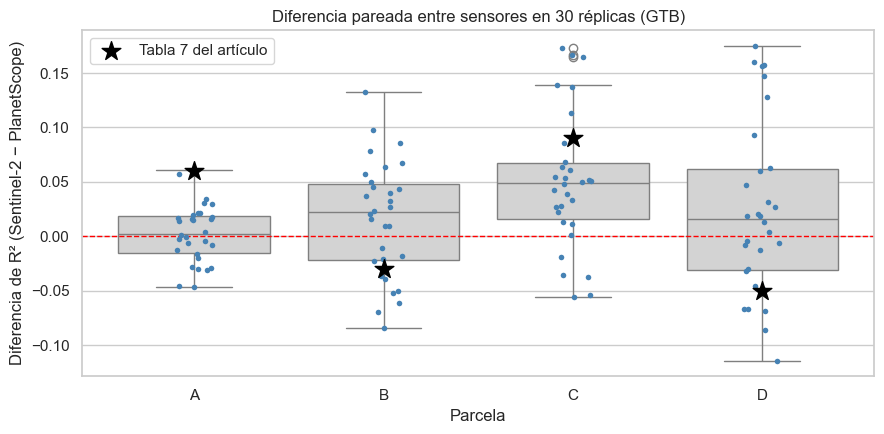

In [6]:
# Escenario: GTB, estrategia multivariada, rendimiento real en las cuatro parcelas
sensores = replicas[(replicas["modelo"] == "GTB") & (replicas["estrategia"] == "multivariada")
                    & (replicas["respuesta"] == "rendimiento")]

# Diferencia pareada Sentinel-2 − PlanetScope en cada réplica
ancho = sensores.pivot_table(index=["replica", "parcela"], columns="sensor",
                             values=["pru_r2", "pru_rmse"])
pareada = pd.DataFrame({
    "dif_r2": ancho["pru_r2"]["Sentinel-2"] - ancho["pru_r2"]["PlanetScope"],
    "dif_rmse": ancho["pru_rmse"]["Sentinel-2"] - ancho["pru_rmse"]["PlanetScope"],
}).reset_index()

resumen_sensores = pareada.groupby("parcela").agg(
    dif_r2=("dif_r2", "mean"),
    r2_ic_inf=("dif_r2", lambda s: s.quantile(0.025)),
    r2_ic_sup=("dif_r2", lambda s: s.quantile(0.975)),
    replicas_gana_S2=("dif_r2", lambda s: (s > 0).mean()),
    dif_rmse=("dif_rmse", "mean"),
)
# Diferencias de la Tabla 7 del artículo (Sentinel-2 − PlanetScope, GTB)
resumen_sensores["dif_r2_tabla7"] = [
    config.METRICAS_ARTICULO["Sentinel-2"][p]["GTB"][2] - config.METRICAS_ARTICULO["PlanetScope"][p]["GTB"][2]
    for p in resumen_sensores.index
]
display(resumen_sensores.round(3))
resumen_sensores.to_csv(config.DIR_RESULTADOS / "02_comparacion_sensores.csv")

# Gráfica: distribución de la diferencia pareada en las 30 réplicas
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=pareada, x="parcela", y="dif_r2", color="lightgray", ax=ax)
sns.stripplot(data=pareada, x="parcela", y="dif_r2", color="steelblue", size=4, ax=ax)
ax.scatter(range(4), resumen_sensores["dif_r2_tabla7"], marker="*", s=200, color="black",
           zorder=5, label="Tabla 7 del artículo")
ax.axhline(0, color="red", lw=1, ls="--")
ax.set(xlabel="Parcela", ylabel="Diferencia de R² (Sentinel-2 − PlanetScope)",
       title="Diferencia pareada entre sensores en 30 réplicas (GTB)")
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(config.DIR_FIGURAS / "02_comparacion_sensores.png", dpi=150)
plt.show()

**Resultado.**

| Parcela | Diferencia media de R² (S2 − PS) | Intervalo del 95 % | Réplicas en que gana Sentinel-2 | Tabla 7 |
|---|---|---|---|---|
| A | +0,003 | −0,046 a +0,059 | 53 % | +0,06 |
| B | +0,016 | −0,073 a +0,107 | 63 % | −0,03 |
| C | +0,050 | −0,054 a +0,168 | 83 % | +0,09 |
| D | +0,024 | −0,094 a +0,164 | 57 % | −0,05 |

*1. No hay un sensor claramente superior.* Sentinel-2 obtiene en promedio un R² algo mayor y un RMSE algo menor, coherente con su menor ruido supuesto, pero los cuatro intervalos del 95 % incluyen el 0. Con una sola partición, cualquiera de los dos sensores puede resultar ganador por azar.

*2. Los resultados mezclados de la Tabla 7 son compatibles con el azar.* Las cuatro diferencias reportadas por el artículo caen dentro de la distribución de las 30 réplicas (la de A, en el borde superior). Los signos contrarios entre parcelas son lo esperable cuando dos sensores rinden casi igual y se comparan con una sola partición.

*3. La ventaja de Sentinel-2 es más consistente en C* (83 % de las réplicas), la parcela con menor variabilidad de rendimiento: allí el ruido del sensor pesa más en relación con la señal.

*Actualización del hallazgo 9.* La conclusión del artículo de que Sentinel-2 superó a PlanetScope en las cuatro parcelas no se sostiene ni en su Tabla 7 ni en la simulación; la evidencia indica un desempeño comparable entre ambos sensores. La diferencia de ruido entre sensores (2,0 % frente a 2,5 %) es un supuesto calibrado; la conclusión depende de que las diferencias reales entre sensores sean de ese orden. Para aplicaciones como la del trabajo de grado, el resultado favorece a Sentinel-2: es gratuito y no pierde desempeño frente a un sensor comercial de mayor resolución.

## 7. B y D: respuesta interpolada frente a real (fuga por interpolación)

En las parcelas de excavación se comparan tres escenarios con el mismo modelo, los mismos predictores y la misma partición en cada réplica:

1. **Entrena y evalúa con el rendimiento real:** lo que se lograría con mediciones directas en cada punto.
2. **Entrena y evalúa con el rendimiento interpolado:** el procedimiento del artículo.
3. **Entrena con el interpolado y evalúa con el real:** lo que el modelo del artículo lograría al predecir el rendimiento real del lote.

El escenario 3 requiere entrenar con una respuesta y evaluar con otra, por lo que se vuelven a generar las 30 bases (unos 1,5 minutos de cálculo).

escenario                   1. Entrena y evalúa con el real  \
parcela sensor      modelo                                    
B       PlanetScope CART                               0.37   
                    GTB                                0.63   
                    RF                                 0.67   
        Sentinel-2  CART                               0.41   
                    GTB                                0.64   
                    RF                                 0.69   
D       PlanetScope CART                               0.34   
                    GTB                                0.58   
                    RF                                 0.62   
        Sentinel-2  CART                               0.39   
                    GTB                                0.61   
                    RF                                 0.65   

escenario                   2. Entrena y evalúa con el interpolado (artículo)  \
parcela sensor      modelo                                                      
B       PlanetScope CART                                                -1.09   
                    GTB                                                 -0.24   
                    RF                                                  -0.05   
        Sentinel-2  CART                                                -1.03   
                    GTB                                                 -0.24   
                    RF                                                  -0.07   
D       PlanetScope CART                                                -1.15   
                    GTB                                                 -0.28   
                    RF                                                  -0.09   
        Sentinel-2  CART                                                -1.21   
                    GTB                                                 -0.28   
                    RF                                                  -0.09   

escenario                   3. Entrena con el interpolado, evalúa con el real  \
parcela sensor      modelo                                                      
B       PlanetScope CART                                                -0.25   
                    GTB                                                 -0.02   
                    RF                                                   0.04   
        Sentinel-2  CART                                                -0.20   
                    GTB                                                 -0.00   
                    RF                                                   0.04   
D       PlanetScope CART                                                -0.25   
                    GTB                                                 -0.06   
                    RF                                                   0.01   
        Sentinel-2  CART                                                -0.28   
                    GTB                                                 -0.05   
                    RF                                                   0.01   

escenario                   articulo  
parcela sensor      modelo            
B       PlanetScope CART        0.60  
                    GTB         0.68  
                    RF          0.61  
        Sentinel-2  CART        0.60  
                    GTB         0.65  
                    RF          0.65  
D       PlanetScope CART        0.69  
                    GTB         0.67  
                    RF          0.62  
        Sentinel-2  CART        0.69  
                    GTB         0.62  
                    RF          0.61

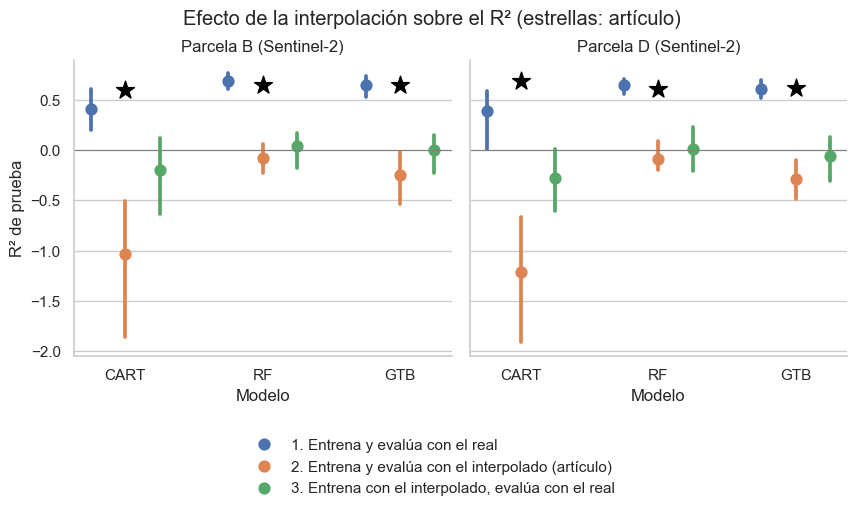

In [7]:
from src.simulacion import generar_base
from src.modelos import construir_modelo
from src.evaluacion import particion_aleatoria, calcular_metricas

# Escenarios 2 y 3: entrenar con el interpolado y evaluar contra ambas respuestas
filas = []
for replica in range(config.N_REPLICAS):
    semilla = config.SEMILLA + replica
    base_replica = generar_base(semilla=semilla, guardar=False)
    seleccion = base_replica[base_replica["parcela"].isin(["B", "D"])
                             & (base_replica["estrategia"] == "multivariada")
                             & (base_replica["tipo_punto"] == "muestreo")]
    for (parcela, sensor), datos in seleccion.groupby(["parcela", "sensor"]):
        X = datos[config.PREDICTORES].to_numpy()
        y_interpolado = datos["rendimiento_interpolado"].to_numpy()
        y_real = datos["rendimiento"].to_numpy()
        ent, pru = particion_aleatoria(len(X), semilla)
        for modelo in config.MODELOS:
            ajustado = construir_modelo(modelo, sensor, parcela, semilla).fit(X[ent], y_interpolado[ent])
            prediccion = ajustado.predict(X[pru])
            filas.append({
                "replica": replica, "parcela": parcela, "sensor": sensor, "modelo": modelo,
                "r2_vs_interpolado": calcular_metricas(y_interpolado[pru], prediccion)["r2"],
                "r2_vs_real": calcular_metricas(y_real[pru], prediccion)["r2"],
            })
cruzada = pd.DataFrame(filas)
cruzada.to_csv(config.DIR_RESULTADOS / "02_interpolacion_cruzada.csv", index=False)

# Escenario 1: entrena y evalúa con el real (ya está en las réplicas)
directo = replicas[replicas["parcela"].isin(["B", "D"]) & (replicas["estrategia"] == "multivariada")
                   & (replicas["respuesta"] == "rendimiento")]

escenarios = pd.concat([
    directo.assign(escenario="1. Entrena y evalúa con el real", r2=directo["pru_r2"]),
    cruzada.assign(escenario="2. Entrena y evalúa con el interpolado (artículo)", r2=cruzada["r2_vs_interpolado"]),
    cruzada.assign(escenario="3. Entrena con el interpolado, evalúa con el real", r2=cruzada["r2_vs_real"]),
])[["replica", "parcela", "sensor", "modelo", "escenario", "r2"]]

resumen_interpolacion = (escenarios.groupby(["parcela", "sensor", "modelo", "escenario"])["r2"]
                         .mean().unstack("escenario"))
resumen_interpolacion["articulo"] = [config.METRICAS_ARTICULO[s][p][m][2]
                                     for p, s, m in resumen_interpolacion.index]
display(resumen_interpolacion.round(2))
resumen_interpolacion.to_csv(config.DIR_RESULTADOS / "02_efecto_interpolacion.csv")

# Gráfica (Sentinel-2)
s2 = escenarios[escenarios["sensor"] == "Sentinel-2"]
g = sns.catplot(data=s2, x="modelo", y="r2", hue="escenario", col="parcela", kind="point",
                errorbar=("pi", 95), dodge=0.5, linestyle="none", order=config.MODELOS,
                height=4, aspect=1.1, legend_out=False)
for parcela, ax in g.axes_dict.items():
    for k, modelo in enumerate(config.MODELOS):
        ax.scatter(k, config.METRICAS_ARTICULO["Sentinel-2"][parcela][modelo][2],
                   marker="*", s=180, color="black", zorder=5)
    ax.axhline(0, color="gray", lw=0.8)
g.set_axis_labels("Modelo", "R² de prueba")
g.set_titles("Parcela {col_name} (Sentinel-2)")
sns.move_legend(g, "lower center", bbox_to_anchor=(0.5, -0.22), ncol=1, title=None, frameon=False)
g.figure.suptitle("Efecto de la interpolación sobre el R² (estrellas: artículo)", y=1.03)
g.savefig(config.DIR_FIGURAS / "02_efecto_interpolacion.png", dpi=150, bbox_inches="tight")
plt.show()

**Resultado.** R² medio de prueba en B y D (30 réplicas):

| Escenario | RF y GTB | CART | Artículo |
|---|---|---|---|
| 1. Entrena y evalúa con el real | 0,58–0,69 | 0,34–0,41 | 0,60–0,69 |
| 2. Entrena y evalúa con el interpolado (artículo) | −0,29 a −0,05 | −1,21 a −1,03 | |
| 3. Entrena con el interpolado, evalúa con el real | −0,06 a +0,04 | −0,28 a −0,20 | |

*1. Los R² del artículo en B y D solo se reproducen con mediciones directas.* El escenario 1 coincide con el artículo en RF y GTB. Con el procedimiento declarado por los autores (escenario 2), bajo el supuesto de manchas de rendimiento de 30 a 50 m, los R² son negativos.

*2. Un modelo entrenado con la superficie interpolada no predice el rendimiento real.* En el escenario 3, el R² frente al rendimiento real es prácticamente cero: el modelo aprende una superficie suavizada que casi no contiene información del lote y no transfiere capacidad predictiva al campo.

*3. El problema está en la variable respuesta, no en el algoritmo.* Los mismos predictores y modelos obtienen R² de 0,6–0,7 o de 0 según la calidad del dato de verdad de terreno. Con 30 mediciones separadas 65 m no es posible reconstruir un lote con manchas de 30 a 50 m.

*Interpretación de la fuga por interpolación (medida R4).* Bajo estos supuestos, los R² reportados en B y D no pueden interpretarse como capacidad de predecir el rendimiento real. Hay dos explicaciones compatibles con el artículo: que la variabilidad real de esos lotes fuera de mayor escala (manchas mucho mayores que 65 m), de modo que 30 mediciones bastaran para representarla, o que la superficie evaluada conservara más variabilidad de la que permiten 30 mediciones. La extensión experimental pondrá a prueba la primera mediante la sensibilidad al alcance de la autocorrelación (medida R6).

*Implicación para el trabajo de grado.* La calidad, la escala y la densidad del dato de verdad de terreno pueden pesar más que la elección del algoritmo. En un modelo con predictores satelitales de 10 m y una respuesta agregada (como el rendimiento municipal), este aspecto debe tratarse explícitamente en el diseño metodológico.

## 8. Síntesis de la recreación y la comparación

### Qué se recreó

| Elemento del artículo | Recreación | ¿Coincide? |
|---|---|---|
| Procedimiento: partición 70/30 por parcela, 8 predictores, CART, RF y GTB con los hiperparámetros de la Tabla 3 | Igual, con los valores no reportados tomados de los valores por defecto de Earth Engine | Sí |
| R² de prueba en A y C | 8 de 12 valores del artículo dentro del intervalo del 95 % | Sí, salvo el orden de los modelos |
| R² de prueba en B y D (respuesta interpolada) | R² negativos; ningún valor del artículo dentro del intervalo | No |
| R² de prueba en B y D (respuesta real) | RF y GTB: 0,58–0,69, como el artículo | Sí |
| Comparación de sensores (Tabla 7) | Diferencias compatibles con el azar | Sí, pero la conclusión del artículo no se sostiene |
| R² de entrenamiento | 0,97–1,00 en CART y GTB, frente a 0,66–0,84 | No |

### Por qué difieren los resultados

| Diferencia | Explicación más probable | Sección |
|---|---|---|
| RF supera a CART en la simulación; en el artículo rinden parecido | Con ~2 puntos por hoja, un árbol único tiene alta varianza; en datos suavizados por interpolación, memorizar vecinos puede parecer buen desempeño | 3 |
| B y D no se reproducen con la respuesta interpolada | Con manchas de 30–50 m y mediciones cada 65 m, la superficie interpolada casi no contiene información del lote; los resultados del artículo son compatibles con una variabilidad de mayor escala o con una respuesta más variable que la descrita | 3 y 7 |
| R² y RMSE inconsistentes entre modelos | En ninguna combinación los tres modelos se evaluaron con la ecuación 5 sobre un mismo conjunto de prueba; en C es compatible con el r², en A sugiere particiones distintas por modelo | 4 |
| R² de entrenamiento bajos y brecha constante (0,05–0,08) | El R² de "entrenamiento" del artículo probablemente no se calculó por resustitución | 5 |
| Signos mezclados en la Tabla 7 | Con sensores de desempeño comparable, una sola partición produce ganadores aleatorios | 6 |

### Hallazgos actualizados

- **Hallazgo 1** (R² frente a RMSE): se generaliza a las ocho combinaciones de parcela y sensor.
- **Hallazgo 9** (sensores): la evidencia indica un desempeño comparable, no una superioridad de Sentinel-2.
- **Hallazgo 11** (una sola partición): confirmado; la variación entre réplicas (por ejemplo, ±0,16 en CART) es del mismo orden que las diferencias que el artículo interpreta.
- **Hallazgo 13** (R² de entrenamiento): confirmado.
- **Fuga por interpolación**: cuantificada. Bajo los supuestos del generador, un modelo entrenado con la superficie interpolada no predice el rendimiento real (R² ≈ 0).

### Lo que queda para la extensión experimental

1. **Fuga espacial:** comparar la partición aleatoria del artículo con validación por bloques, por bloques con zona de exclusión y por parcela.
2. **Sensibilidad al alcance:** comprobar si, con manchas de mayor tamaño, la interpolación conserva suficiente variabilidad para explicar los resultados del artículo en B y D.
3. **Línea base lineal:** contrastar los modelos del artículo con una regresión simple, dado que la correlación del NDVI con el rendimiento dentro de las parcelas (hasta 0,93) sugiere que un modelo lineal podría rendir tan bien como los árboles.
4. **Selección de hiperparámetros sin fuga:** validación cruzada anidada frente al ajuste manual del artículo.